## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 
import pyarrow

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

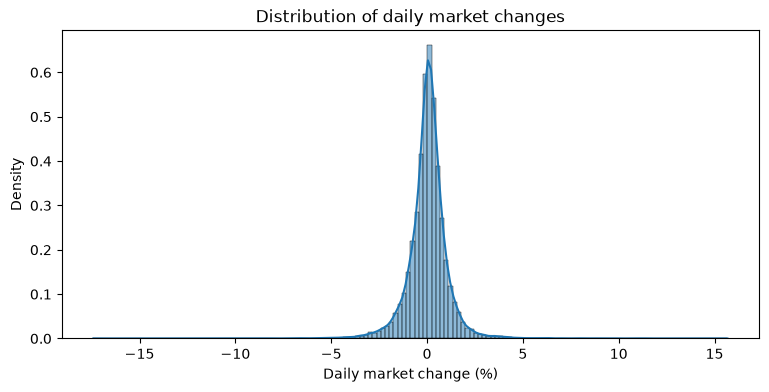

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

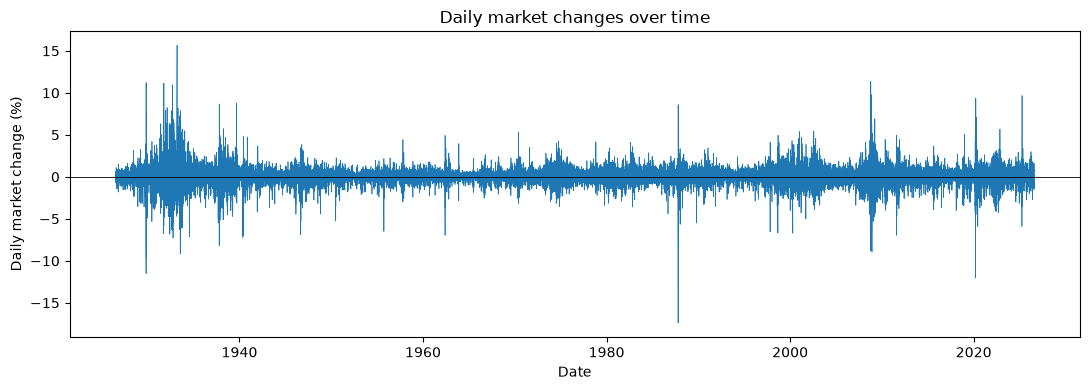

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [4]:
df['r_t'] = df['market_return_pct']
df['r_tp1'] = df['market_return_pct'].shift(-1)

df['y_t'] = np.where(df['r_t'] > 0, 'Up', 'Down/flat')
df['y_tp1'] = df['y_t'].shift(-1)

print('Counts:')
display(pd.crosstab(df['y_t'], df['y_tp1']))

print('Joint PMF w/ marginals:')
display(pd.crosstab(df['y_t'], df['y_tp1'], normalize=True, margins=True))

print('Conditional PMF/P(tomorrow|today):')
display(pd.crosstab(df['y_t'], df['y_tp1'], normalize='index'))

Counts:


y_tp1,Down/flat,Up
y_t,,
Down/flat,5909,5999
Up,5999,8388


Joint PMF w/ marginals:


y_tp1,Down/flat,Up,All
y_t,,,
Down/flat,0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


Conditional PMF/P(tomorrow|today):


y_tp1,Down/flat,Up
y_t,,
Down/flat,0.496221,0.503779
Up,0.416974,0.583026


1. Up transitions are more common than down transitions because 54.7% of days move to an Up day, compared with 45.3% that move to a Down/flat day.
2. P(Up|Up) = 0.583 & P(Up|Down/flat) = 0.504. After an Up day, the chance of another up day rises by ~8 points, which is small but still positive momentum. So, you're more likely to transition to an Up day from an Up day.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [5]:
labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']

df['y_t'] = pd.cut(df['r_t'], bins=[-np.inf, -1, -0.1, 0.1, 1, np.inf], labels=labels)

df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts().reindex(labels)

y_t
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9785
Large gain    2859
Name: count, dtype: int64

1. 
Large loss    2759 -> 10.5% <- LEAST COMMON

Small loss    7452 -> 28.3%

Near zero     3441 -> 13.1%

Small gain    9785 -> 37.2% <- MOST COMMON

Large gain    2859 -> 10.9%

Name: count, dtype: int64

Small gain is most common state and Large loss is the least common state. Most days are small moves.

In [6]:
joint5 = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True, margins=True)
display(joint5.round(3))

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021,0.027,0.009,0.028,0.020,0.105
Small loss,0.035,0.089,0.034,0.098,0.027,0.283
Near zero,0.009,0.042,0.021,0.049,0.009,0.131
Small gain,0.025,0.100,0.055,0.159,0.033,0.372
Large gain,0.014,0.026,0.012,0.038,0.020,0.109
All,0.105,0.283,0.131,0.372,0.109,1.000


2. The transition most likely to occur is Small gain -> Small gain at 0.159. Second most likely is Small gain -> Small loss at 0.1. Third most likely is Small loss -> Small gain at 0.098. Fourth most likely is Small loss -> Small loss at 0.089. So the transitions among the "small" states are the most likely overall - mainly because Small gain and Small loss are the most common states to begin with.

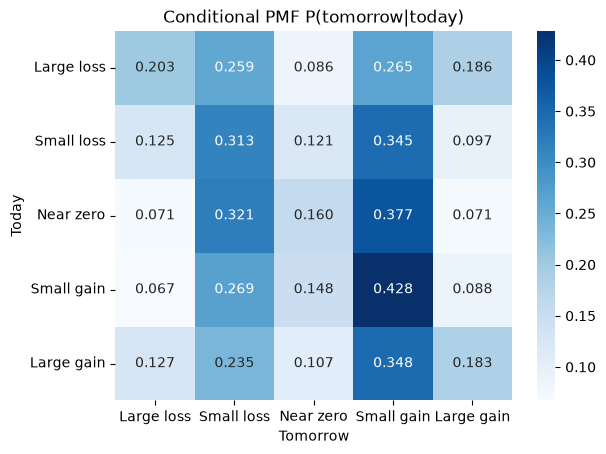

In [7]:
cond5 = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')

sns.heatmap(cond5, annot=True, fmt='.3f', cmap='Blues')
plt.title('Conditional PMF P(tomorrow|today)')
plt.xlabel('Tomorrow')
plt.ylabel('Today')
plt.show()

3. 
Current State -> Two most likely future states:

Large loss -> Small gain at 0.265 and Small loss at 0.259

Small loss -> Small gain at 0.35 and Small loss at 0.31

Near zero -> Small gain at 0.38 and Small loss at 0.32

Small gain-> Small gain at 0.43 and Small loss at 0.27

Large gain -> Small gain at 0.35 and Small loss at 0.23



4. No row is close to uniform (0.2 each), but some rows are closer than others. The Large loss row is closest to uniform. Its values run from 0.086 to 0.265 so after a crash almost anything can happen next. The Small gain row is the furthest from uniform, with 0.428 on Small gain and only 0.067 on Large loss. The Small loss and Near zero rows sit in between the two, and the Large gain row is pretty spread out, like the Large loss row. The next state is hard to predict since every row's most likely next state is Small gain and it's right at most 43% of the time. There is a useful signal though, as after a Large day, the chance of another Large day in either direction ~doubles (0.39 v 0.16). So, after a Large loss the chnace of a Large loss or gain tomorrow is 0.20+0.19 = 0.39, whereas after a Small gain it's 0.07+0.09 = 0.16.


In [8]:
df.groupby('y_t', observed=False)['r_tp1'].describe()

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


5. Given today's state, the expected returns for tomorrow are all pretty tiny, between ~ -0.04% and 0.16%. They do rise slightly from the loss states to the gain states, which matches the mild momentum we see in part 1. But each mean is smaller than the standard deviation so the expected return doesn't tell you much about any single day.

6. After the large states, the min and max tails get much wider. After a large loss, tomorrow ranges from -17,.41% (<- the worst next day in the data) to 11.22%. After a LArge gain, tomorrow ranges from -12.0% to 15.67% (<- the best next day in the data). Small loss days also are followed by wide tails (−11.23% to 11.36%). The narrowest ranges follow Near zero and Small gain days.

7. The states with the highest standard deviation of tomorrow's return in descending order are: Large loss (1.72) -> Large gain (1.38) -> Small loss (1.01) -> Small gain (0.832) -> Near zero (0.826). Large loss & Large gain are the highest. The pattern is volatility clustering, where large moves tend to follow large moves of either sign, and calm days follow calm days. This effect looks to be stronger after losses than after gains which is likely because markets tend to be more turbulent during sell-offs.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [9]:
df['y_t'] = pd.qcut(df['r_t'], 21, labels=False)
df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts().sort_index()

y_t
0     1255
1     1253
2     1286
3     1280
4     1230
5     1226
6     1371
7     1206
8     1198
9     1331
10    1210
11    1223
12    1294
13    1223
14    1310
15    1193
16    1211
17    1283
18    1225
19    1250
20    1238
Name: count, dtype: int64

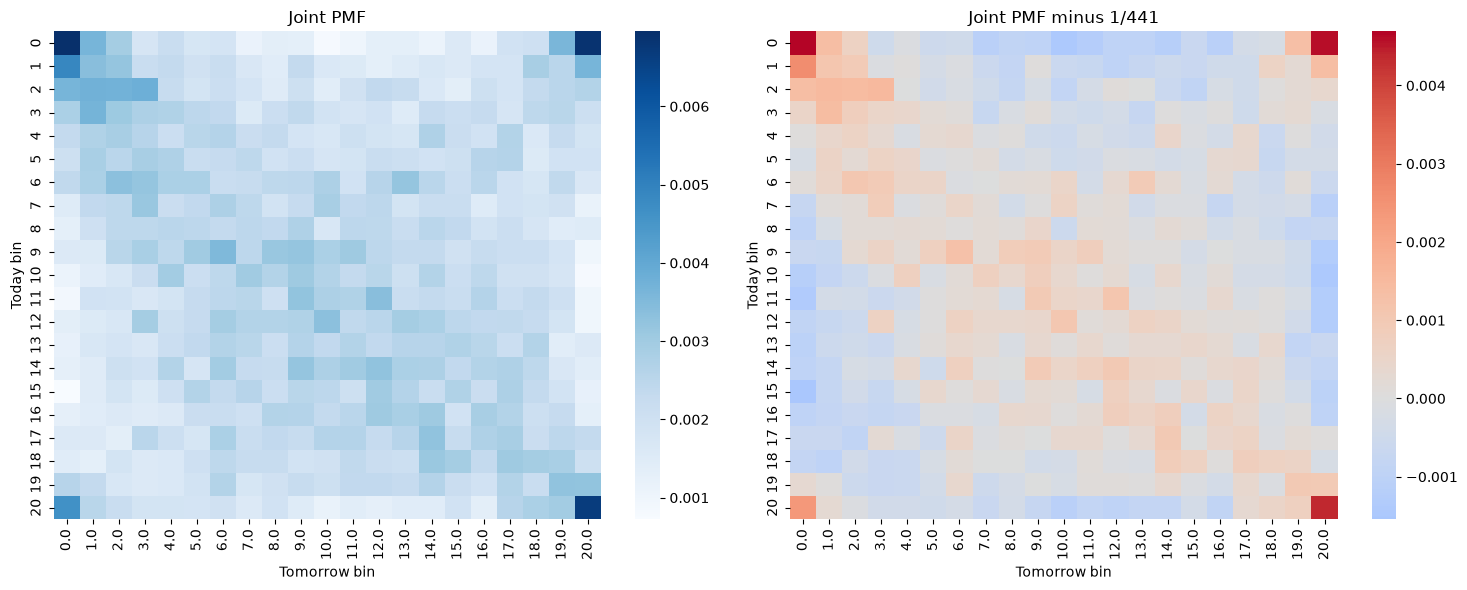

In [10]:
joint21 = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(joint21, cmap='Blues', ax=axes[0])
axes[0].set(title='Joint PMF', xlabel='Tomorrow bin', ylabel='Today bin')

sns.heatmap(joint21 - 1/21**2, cmap='coolwarm', center=0, ax=axes[1])
axes[1].set(title='Joint PMF minus 1/441', xlabel='Tomorrow bin', ylabel='Today bin')
plt.tight_layout()
plt.show()

1. In the raw joint PMF, the obvious pattern is that the four corners have the highest probability associated with them (they are darker than everything else). So, the strongest cells are worst -> worst or bin 0 -> bin 0, best->best or bin 20-> bin20, worst->best or bin 0->bin 20, best-> worst or bin 20->bin 0. 

In the minus-1/441 plot, the four corners are red while the extreme rows going into the middle columns are blue (less frequent than chance), and the center block is slightly red.

So, an extreme day is followed by another extreme day in either direction and a normal day by another normal day. This is the volatility clustering visualized.

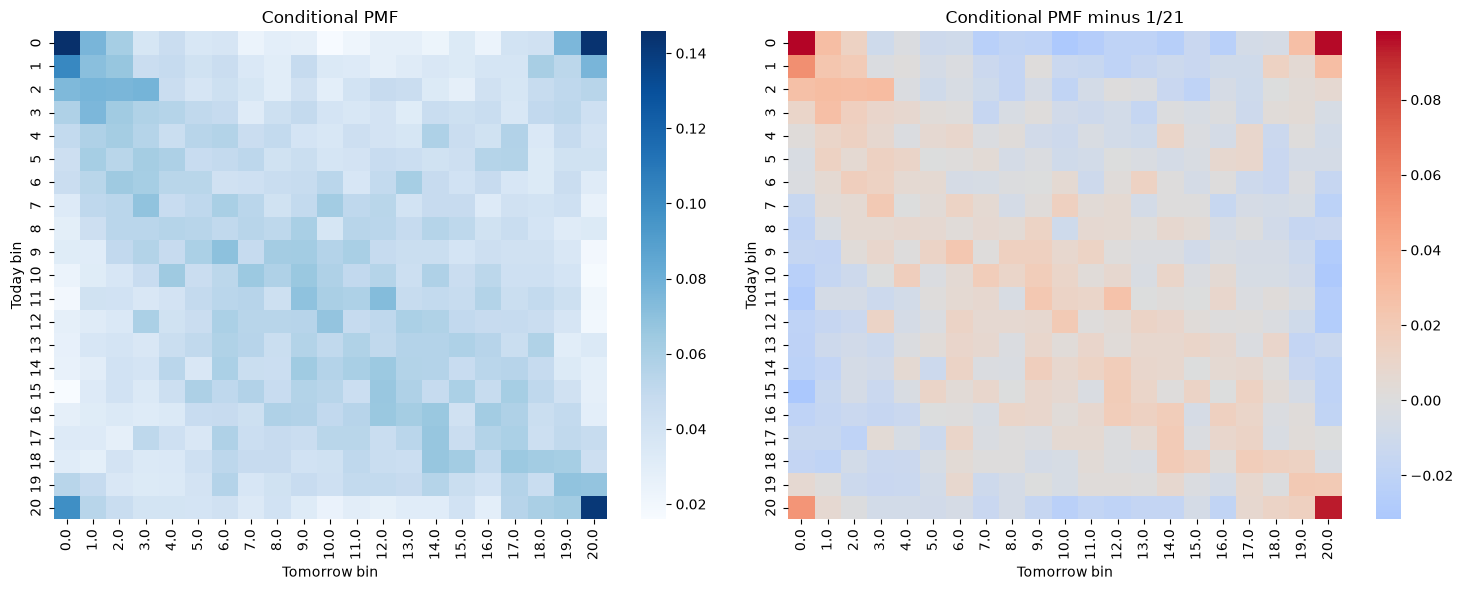

In [11]:
cond21 = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(cond21, cmap='Blues', ax=axes[0])
axes[0].set(title='Conditional PMF', xlabel='Tomorrow bin', ylabel='Today bin')

sns.heatmap(cond21 - 1/21, cmap='coolwarm', center=0, ax=axes[1])
axes[1].set(title='Conditional PMF minus 1/21', xlabel='Tomorrow bin', ylabel='Today bin')
plt.tight_layout()
plt.show()

2. If tomorrow were random then every value in each row would equal 1/21 (~= 0.048). Instead the same corner pattern appears. After a bin 0 day theres a 14.6% chance tomorrow is also bin 0 and a 14.5% chance its bin 20. After a bin 20 day theres a 14.2% chance of bin 20 and 9.9% chance of bin 0. The middle rows from about bin 5-16 stay pretty close to 0.048 so are nearly uniform, meaning after an ordinary day almost any bin is equally likely the next day.

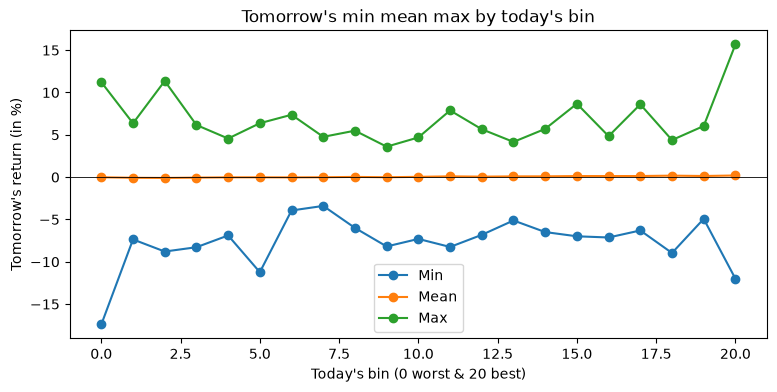

In [12]:
stats21 = df.groupby('y_t')['r_tp1'].agg(['min', 'mean', 'max', 'std'])

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(stats21.index, stats21['min'], marker='o', label='Min')
ax.plot(stats21.index, stats21['mean'], marker='o', label='Mean')
ax.plot(stats21.index, stats21['max'], marker='o', label='Max')
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel="Today's bin (0 worst & 20 best)",
       ylabel="Tomorrow's return (in %)",
       title="Tomorrow's min mean max by today's bin")
ax.legend()
plt.show()

3. The mean line is almost flat near 0 - the range is  ~ -0.1% to ~ 0.2% but on the same scale as min & max it looks like a flat line since bin 0's returns span −17.41% to 11.22%, and bin 20's returns span −12.0% to 15.67%. The min and max fan out at the edges, and are widest at bin 0 and bin 20. They are narrower in the middle bins. Extreme days are followed by the widest range of outcomes even though the average outcome barely changes.

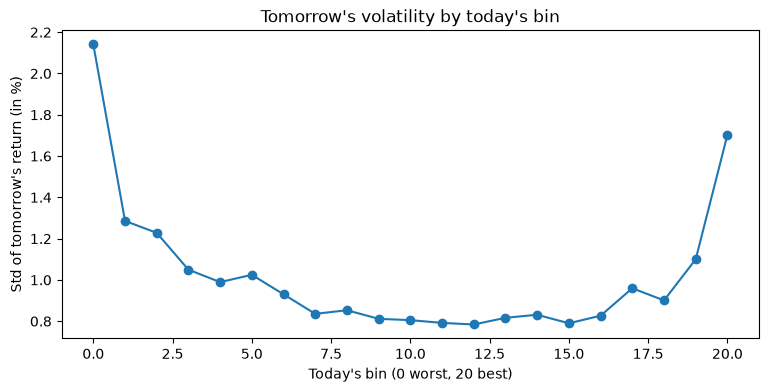

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(stats21.index, stats21['std'], marker='o')
ax.set(xlabel="Today's bin (0 worst, 20 best)",
       ylabel="Std of tomorrow's return (in %)",
       title="Tomorrow's volatility by today's bin")
plt.show()

In [14]:
# Corr btwn return today r_t and return tmrw r_tp1
print(round(df['r_t'].corr(df['r_tp1']), 3))

# Corr btwn size of todays move and size of tmrw's move
print(round(df['r_t'].abs().corr(df['r_tp1'].abs()), 3))

0.046
0.298


4. The standard deviation line is U-shaped. It's high at the edges, ~2.1 after bin 0 and ~1.7 after bin 20. It's lowest in the middle, ranging from ~0.8 to ~1 across bins 5-15. The left side is higher than the right side so big losses lead to more turbulence tomorrow than big gains do. So, today's return size predicts tomorrow's volatility well even though it doesn';t really predict tomorrow's direction.

5. It is not easy to predict the market! For direction, the conditional means are within a fraction of a percent of zero, the middle rows of the transition matrix are close to uniform, and the correlation between today's and tomorrow's return is only 0.046. Predicting volatility is much easier since extreme days cluster together and the standard deviation forms a clear U-shape. The correlation bewteen today's and tomorrow's absolute return is 0.298 (~6x stronger). So you can't tell whether the market will go up tomorrow, but you can tell whether tomorrow is likely to be volatile or not.